# CLIP baseline — TAU 3500 independent evaluation

This notebook follows the same CLIP baseline pipeline used for development.

Preserved:
- `openai/clip-vit-base-patch32`
- 8 frames per video
- centers of equal temporal intervals
- the same 10 fixed TAU prompts
- frame-level CLIP probabilities
- mean frame probabilities for the video prediction
- all 10 scene scores
- Top-1 / Top-2 / Top-3
- checkpoint every 50 videos
- automatic resume
- output directory: `results_CLIP_TEST_3500`

Two reproducibility conveniences are retained:
1. `local_files_only=True` so the already-downloaded CLIP model is used.
2. `FRESH_RUN=True` for the first clean evaluation rerun. Change it to
   `False` if an interrupted run needs to resume from its checkpoint.


C:\Users\22313906t\AppData\Local\anaconda3\envs\tau_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Deleted old output: C:\Users\22313906t\Desktop\TAU_project\results_CLIP_TEST_3500\tau_3500_test_clip_predictions.csv
Deleted old output: C:\Users\22313906t\Desktop\TAU_project\results_CLIP_TEST_3500\tau_3500_test_clip_config.json

Fresh CLIP 3500 evaluation rerun ready.
TAU 3500 EVALUATION CLIP BASELINE
Project:
C:\Users\22313906t\Desktop\TAU_project

Manifest:
C:\Users\22313906t\Desktop\TAU_project\manifests\tau_balanced_3500_test_manifest.csv

Manifest exists: True

MANIFEST CHECK
Rows: 3500
Unique clip IDs: 3500

Class distribution:
ground_truth
airport              350
bus                  350
metro                350
metro station        350
park                 350
public square        350
shopping mall        350
pedestrian street    350
street traffic       350
tram                 350
Name: count, dtype: int64

Missing videos: 0
Video manifest verified.

DEVICE
PyTorch: 2.13.0+cu126
CUDA available: True
GPU: NVIDIA RTX 2000 Ada Generation Laptop GPU
Using: cuda

LOADING CLIP
M

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 9492.67it/s]


Model device: cuda:0

CLIP PROMPTS
airport              -> a photo of an airport
bus                  -> a photo inside or around a bus
metro                -> a photo inside a metro train
metro station        -> a photo of a metro station
park                 -> a photo of a park
public square        -> a photo of a public square
shopping mall        -> a photo inside a shopping mall
pedestrian street    -> a photo of a pedestrian street
street traffic       -> a photo of street traffic
tram                 -> a photo inside or around a tram

Text setup complete.
Text feature type: <class 'torch.Tensor'>
Text feature shape: (10, 512)
Text feature device: cuda:0

ONE-VIDEO TEST
Clip: park-stockholm-245-7322
Ground truth: park
Frames used: 8

Ranking:
 1. park                 0.8874
 2. pedestrian street    0.0596
 3. street traffic       0.0210
 4. public square        0.0200
 5. metro station        0.0048
 6. airport              0.0035
 7. tram                 0.0020
 8. bus        

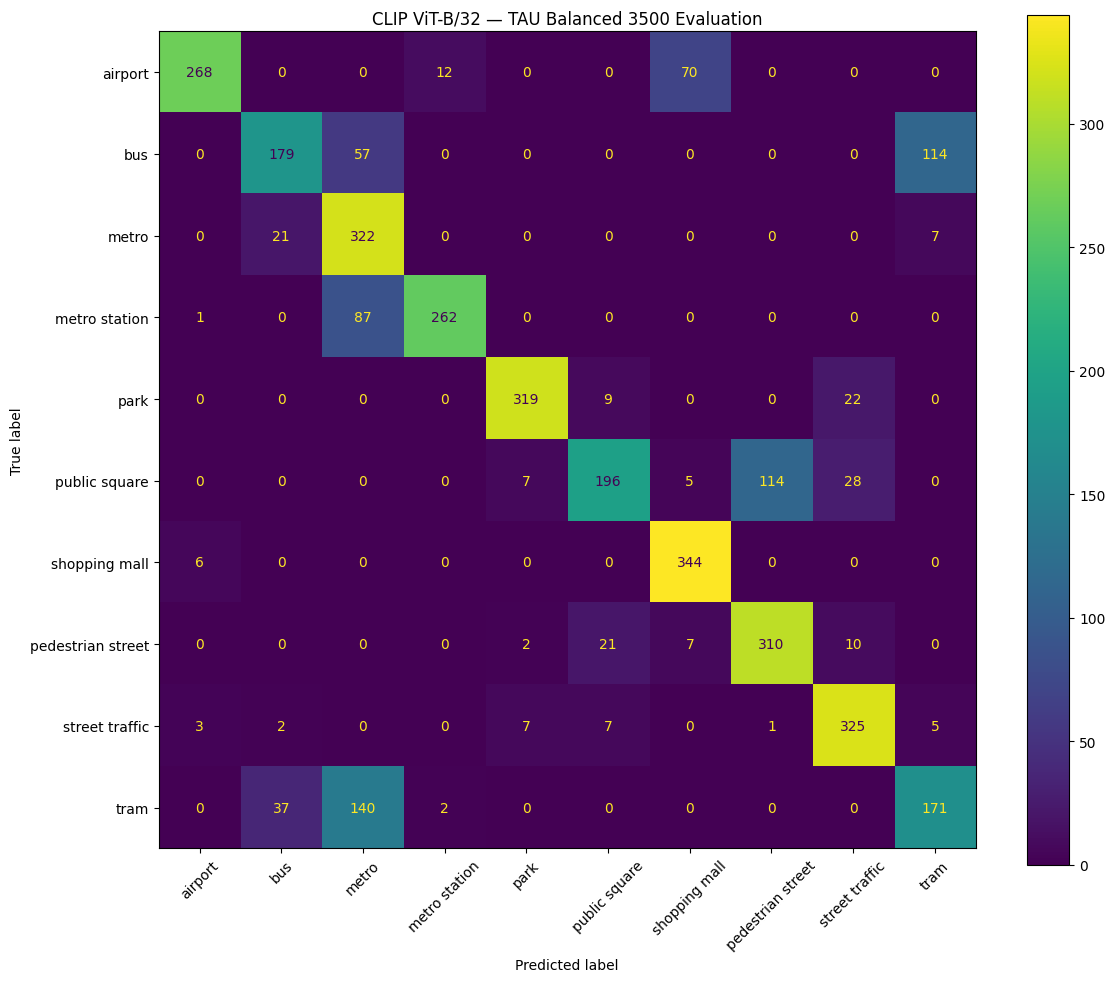


FINAL SUMMARY
                       model  number_of_manifest_clips  number_of_processed_clips  processing_errors  frames_per_video  top1_accuracy  top1_accuracy_percent  top2_recall  top2_recall_percent  top3_recall  top3_recall_percent  macro_f1  top1_errors  top3_recoverable_errors  recoverable_error_percent
openai/clip-vit-base-patch32                      3500                       3500                  0                 8       0.770286              77.028571     0.938286            93.828571     0.994571            99.457143  0.767533          804                      785                  97.636816

FILES SAVED

Main predictions:
C:\Users\22313906t\Desktop\TAU_project\results_CLIP_TEST_3500\tau_3500_test_clip_predictions.csv

Summary:
C:\Users\22313906t\Desktop\TAU_project\results_CLIP_TEST_3500\tau_3500_test_clip_baseline_summary.csv

Per-class:
C:\Users\22313906t\Desktop\TAU_project\results_CLIP_TEST_3500\tau_3500_test_clip_per_class_results.csv

Classification report:
C:\Us

In [1]:
# TAU 3500 independent evaluation CLIP baseline.
# Samples eight frames per video and averages frame-level scene probabilities.

from pathlib import Path
from contextlib import nullcontext
import time
import json
import warnings
import numpy as np
import pandas as pd
import cv2
from PIL import Image
import torch
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

# Project paths
PROJECT_ROOT = Path('C:\\Users\\22313906t\\Desktop\\TAU_project')
MANIFEST_DIR = PROJECT_ROOT / 'manifests'
SUBSET_MANIFEST_PATH = MANIFEST_DIR / 'tau_balanced_3500_test_manifest.csv'
CLIP_RESULTS_DIR = PROJECT_ROOT / 'results_CLIP_TEST_3500'
CLIP_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CLIP_PREDICTIONS_PATH = CLIP_RESULTS_DIR / 'tau_3500_test_clip_predictions.csv'
CLIP_ERRORS_PATH = CLIP_RESULTS_DIR / 'tau_3500_test_clip_errors.csv'
CONFIG_PATH = CLIP_RESULTS_DIR / 'tau_3500_test_clip_config.json'
SUMMARY_PATH = CLIP_RESULTS_DIR / 'tau_3500_test_clip_baseline_summary.csv'
REPORT_PATH = CLIP_RESULTS_DIR / 'tau_3500_test_clip_classification_report.csv'
PER_CLASS_PATH = CLIP_RESULTS_DIR / 'tau_3500_test_clip_per_class_results.csv'
CONFUSION_PATH = CLIP_RESULTS_DIR / 'tau_3500_test_clip_confusion_matrix.png'
ONTOLOGY_OPPORTUNITY_PATH = CLIP_RESULTS_DIR / 'tau_3500_test_clip_ontology_opportunities.csv'

# Fresh-run option
# True  = remove previous CLIP outputs and start the 3500 evaluation run from zero.
# False = keep previous predictions and use the original resume logic.
# For the first clean rerun, leave this as True.
# If the run is interrupted and you want to resume, change it to False.
FRESH_RUN = True
if FRESH_RUN:
    old_output_files = [
        CLIP_PREDICTIONS_PATH,
        CLIP_ERRORS_PATH,
        CONFIG_PATH,
        SUMMARY_PATH,
        REPORT_PATH,
        PER_CLASS_PATH,
        CONFUSION_PATH,
        ONTOLOGY_OPPORTUNITY_PATH,
    ]
    for old_path in old_output_files:
        if old_path.exists():
            old_path.unlink()
            print('Deleted old output:', old_path)
    print('\nFresh CLIP 3500 evaluation rerun ready.')
print('=' * 70)
print('TAU 3500 EVALUATION CLIP BASELINE')
print('=' * 70)
print('Project:')
print(PROJECT_ROOT)
print('\nManifest:')
print(SUBSET_MANIFEST_PATH)
print('\nManifest exists:', SUBSET_MANIFEST_PATH.exists())
if not SUBSET_MANIFEST_PATH.exists():
    raise FileNotFoundError(f'Cannot find manifest:\n{SUBSET_MANIFEST_PATH}')

# Experiment settings
CLIP_MODEL_NAME = 'openai/clip-vit-base-patch32'
NUM_FRAMES = 8
CHECKPOINT_EVERY = 50
TAU_CLASSES = [
    'airport',
    'bus',
    'metro',
    'metro station',
    'park',
    'public square',
    'shopping mall',
    'pedestrian street',
    'street traffic',
    'tram',
]

# Fixed CLIP prompts
CLIP_PROMPTS = {
    'airport': 'a photo of an airport',
    'bus': 'a photo inside or around a bus',
    'metro': 'a photo inside a metro train',
    'metro station': 'a photo of a metro station',
    'park': 'a photo of a park',
    'public square': 'a photo of a public square',
    'shopping mall': 'a photo inside a shopping mall',
    'pedestrian street': 'a photo of a pedestrian street',
    'street traffic': 'a photo of street traffic',
    'tram': 'a photo inside or around a tram',
}

# Load the exact 3500-recording manifest
video_df = pd.read_csv(SUBSET_MANIFEST_PATH)
required_columns = {'clip_id', 'ground_truth', 'video_path'}
missing_columns = required_columns - set(video_df.columns)
if missing_columns:
    raise ValueError('Manifest is missing columns: ' + str(missing_columns))
video_df['clip_id'] = video_df['clip_id'].astype(str)
video_df['ground_truth'] = video_df['ground_truth'].astype(str)
print('\n' + '=' * 70)
print('MANIFEST CHECK')
print('=' * 70)
print('Rows:', len(video_df))
print('Unique clip IDs:', video_df['clip_id'].nunique())
print('\nClass distribution:')
class_counts = video_df['ground_truth'].value_counts().reindex(TAU_CLASSES)
print(class_counts)
if video_df['clip_id'].duplicated().any():
    raise ValueError('Duplicate clip IDs found in manifest.')
unknown_labels = ~video_df['ground_truth'].isin(TAU_CLASSES)
if unknown_labels.any():
    print('\nUnknown labels:')
    print(video_df.loc[unknown_labels, ['clip_id', 'ground_truth']].head(50))
    raise ValueError('Unknown TAU labels found.')

# Verify video files exist
video_exists = video_df['video_path'].apply(lambda p: Path(p).exists())
missing_video_count = (~video_exists).sum()
print('\nMissing videos:', missing_video_count)
if missing_video_count > 0:
    print(video_df.loc[~video_exists, ['clip_id', 'video_path']].head(30))
    raise FileNotFoundError(f'{missing_video_count} video files are missing.')
print('Video manifest verified.')

# GPU / device
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('\n' + '=' * 70)
print('DEVICE')
print('=' * 70)
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
print('Using:', DEVICE)

# Save experiment configuration
config = {
    'model': CLIP_MODEL_NAME,
    'number_of_videos': int(len(video_df)),
    'num_frames_per_video': NUM_FRAMES,
    'frame_sampling': 'centers_of_equal_temporal_intervals',
    'aggregation': 'mean_of_frame_class_probabilities',
    'classes': TAU_CLASSES,
    'prompts': CLIP_PROMPTS,
    'checkpoint_every': CHECKPOINT_EVERY,
    'device': DEVICE,
}
with open(CONFIG_PATH, 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=2)

# Load CLIP model
print('\n' + '=' * 70)
print('LOADING CLIP')
print('=' * 70)
print('Model:', CLIP_MODEL_NAME)
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME, local_files_only=True)
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME, local_files_only=True)
clip_model = clip_model.to(DEVICE)
clip_model.eval()
print('Model device:', next(clip_model.parameters()).device)

# Helper for new + old transformers versions
def extract_clip_embedding(model_output):
    """
    New Transformers:
        BaseModelOutputWithPooling
        -> projected embedding in .pooler_output

    Older Transformers:
        may directly return torch.Tensor
    """
    if isinstance(model_output, torch.Tensor):
        return model_output
    if hasattr(model_output, 'pooler_output'):
        return model_output.pooler_output
    if isinstance(model_output, (tuple, list)):
        if len(model_output) > 1 and isinstance(model_output[1], torch.Tensor):
            return model_output[1]
    raise TypeError(f'Could not extract CLIP embedding from output type: {type(model_output)}')

# Create text features once
PROMPT_TEXTS = [CLIP_PROMPTS[scene] for scene in TAU_CLASSES]
print('\n' + '=' * 70)
print('CLIP PROMPTS')
print('=' * 70)
for scene, prompt in zip(TAU_CLASSES, PROMPT_TEXTS):
    print(f'{scene:20s} -> {prompt}')
text_inputs = clip_processor(text=PROMPT_TEXTS, return_tensors='pt', padding=True)
text_inputs = {key: value.to(DEVICE) for key, value in text_inputs.items()}
with torch.inference_mode():
    text_output = clip_model.get_text_features(**text_inputs)
    text_features = extract_clip_embedding(text_output)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)
print('\nText setup complete.')
print('Text feature type:', type(text_features))
print('Text feature shape:', tuple(text_features.shape))
print('Text feature device:', text_features.device)
if text_features.shape[0] != 10:
    raise RuntimeError('Expected 10 CLIP text features.')

# Video frame sampling function
def sample_video_frames(video_path, num_frames=8):
    video_path = str(video_path)
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise RuntimeError('Cannot open video: ' + video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(cap.get(cv2.CAP_PROP_FPS))
    if total_frames <= 0:
        cap.release()
        raise RuntimeError('Video reports zero frames: ' + video_path)
    n = min(num_frames, total_frames)
    positions = ((np.arange(n) + 0.5) / n * total_frames).astype(int)
    positions = np.clip(positions, 0, total_frames - 1)
    frames = []
    for frame_index in positions:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index))
        success, frame = cap.read()
        if not success:
            continue
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append(Image.fromarray(frame))
    cap.release()
    if len(frames) == 0:
        raise RuntimeError('No readable frames: ' + video_path)
    return frames

# CLIP frame inference
def classify_clip_frames(frames):
    image_inputs = clip_processor(images=frames, return_tensors='pt')
    pixel_values = image_inputs['pixel_values'].to(DEVICE)
    if DEVICE == 'cuda':
        precision_context = torch.autocast(device_type='cuda', dtype=torch.float16)
    else:
        precision_context = nullcontext()
    with torch.inference_mode():
        with precision_context:
            image_output = clip_model.get_image_features(pixel_values=pixel_values)
            image_features = extract_clip_embedding(image_output)
            image_features = image_features / image_features.norm(dim=-1, keepdim=True)
            logit_scale = clip_model.logit_scale.exp()
            logits = logit_scale * (image_features @ text_features.T)
            probabilities = logits.softmax(dim=-1)
    return probabilities.float().cpu().numpy()

# Video-level classification
def classify_clip_video(video_path, num_frames=8):
    frames = sample_video_frames(video_path=video_path, num_frames=num_frames)
    frame_probs = classify_clip_frames(frames)
    video_probs = frame_probs.mean(axis=0)
    video_probs = video_probs / video_probs.sum()
    sorted_indices = np.argsort(video_probs)[::-1]
    ranking = [{'label': TAU_CLASSES[index], 'score': float(video_probs[index])} for index in sorted_indices]
    scores = {TAU_CLASSES[i]: float(video_probs[i]) for i in range(len(TAU_CLASSES))}
    return {'num_frames_used': len(frames), 'ranking': ranking, 'scores': scores}

# Test one video before full run
print('\n' + '=' * 70)
print('ONE-VIDEO TEST')
print('=' * 70)
test_row = video_df.iloc[0]
print('Clip:', test_row['clip_id'])
print('Ground truth:', test_row['ground_truth'])
test_result = classify_clip_video(video_path=test_row['video_path'], num_frames=NUM_FRAMES)
print('Frames used:', test_result['num_frames_used'])
print('\nRanking:')
for rank, item in enumerate(test_result['ranking'], start=1):
    print(f"{rank:2d}. {item['label']:20s} {item['score']:.4f}")
print('\nOne-video test successful.')

# Load previous checkpoint for automatic resume
print('\n' + '=' * 70)
print('CHECKPOINT / RESUME')
print('=' * 70)
if CLIP_PREDICTIONS_PATH.exists():
    existing_predictions_df = pd.read_csv(CLIP_PREDICTIONS_PATH)
    existing_predictions_df['clip_id'] = existing_predictions_df['clip_id'].astype(str)
    processed_ids = set(existing_predictions_df['clip_id'])
else:
    existing_predictions_df = pd.DataFrame()
    processed_ids = set()
if CLIP_ERRORS_PATH.exists():
    existing_errors_df = pd.read_csv(CLIP_ERRORS_PATH)
else:
    existing_errors_df = pd.DataFrame()
print('Already processed:', len(processed_ids))
remaining_df = video_df[~video_df['clip_id'].isin(processed_ids)].copy().reset_index(drop=True)
print('Remaining:', len(remaining_df))

# Checkpoint buffers
new_prediction_rows = []
new_error_rows = []


def save_checkpoint():
    global existing_predictions_df
    global existing_errors_df
    global new_prediction_rows
    global new_error_rows
    if len(new_prediction_rows) > 0:
        new_df = pd.DataFrame(new_prediction_rows)
        existing_predictions_df = pd.concat([existing_predictions_df, new_df], ignore_index=True)
        existing_predictions_df['clip_id'] = existing_predictions_df['clip_id'].astype(str)
        existing_predictions_df = existing_predictions_df.drop_duplicates(
            subset=['clip_id'],
            keep='last',
        )
        existing_predictions_df.to_csv(CLIP_PREDICTIONS_PATH, index=False)
        new_prediction_rows.clear()
    if len(new_error_rows) > 0:
        new_errors = pd.DataFrame(new_error_rows)
        existing_errors_df = pd.concat([existing_errors_df, new_errors], ignore_index=True)
        existing_errors_df.to_csv(CLIP_ERRORS_PATH, index=False)
        new_error_rows.clear()

# Full CLIP run
print('\n' + '=' * 70)
print('STARTING FULL CLIP RUN')
print('=' * 70)
print('Videos to process:', len(remaining_df))
print('Frames/video:', NUM_FRAMES)
print('Checkpoint every:', CHECKPOINT_EVERY)
start_time = time.time()
since_checkpoint = 0
for idx, row in remaining_df.iterrows():
    clip_id = str(row['clip_id'])
    ground_truth = str(row['ground_truth'])
    video_path = str(row['video_path'])
    try:
        result = classify_clip_video(video_path=video_path, num_frames=NUM_FRAMES)
        ranking = result['ranking']
        prediction_row = {
            'clip_id': clip_id,
            'ground_truth': ground_truth,
            'num_frames_used': result['num_frames_used'],
            'clip_top1': ranking[0]['label'],
            'clip_top1_score': ranking[0]['score'],
            'clip_top2': ranking[1]['label'],
            'clip_top2_score': ranking[1]['score'],
            'clip_top3': ranking[2]['label'],
            'clip_top3_score': ranking[2]['score'],
            'top1_top2_margin': ranking[0]['score'] - ranking[1]['score'],
        }
        for scene in TAU_CLASSES:
            column_name = scene.replace(' ', '_') + '_score'
            prediction_row[column_name] = result['scores'][scene]
        new_prediction_rows.append(prediction_row)
    except Exception as e:
        print('\nERROR:', clip_id, str(e))
        new_error_rows.append({'clip_id': clip_id, 'ground_truth': ground_truth, 'video_path': video_path, 'error': str(e)})
    since_checkpoint += 1
    if (idx + 1) % 25 == 0 or idx == 0:
        elapsed = time.time() - start_time
        rate = (idx + 1) / elapsed if elapsed > 0 else 0
        print(f'[{idx + 1:4d}/{len(remaining_df):4d}] {ground_truth:20s} | {clip_id} | {rate:.2f} videos/s')
    if since_checkpoint >= CHECKPOINT_EVERY:
        save_checkpoint()
        since_checkpoint = 0
        total_saved = len(existing_predictions_df)
        print(f'----- CHECKPOINT SAVED ({total_saved} predictions) -----')

# Final checkpoint
save_checkpoint()
elapsed_minutes = (time.time() - start_time) / 60
print('\n' + '=' * 70)
print('CLIP PROCESSING FINISHED')
print('=' * 70)
print('Elapsed minutes:', round(elapsed_minutes, 2))

# Load final predictions
if not CLIP_PREDICTIONS_PATH.exists():
    raise RuntimeError('No CLIP prediction file was created.')
clip_df = pd.read_csv(CLIP_PREDICTIONS_PATH)
clip_df['clip_id'] = clip_df['clip_id'].astype(str)

# Only keep IDs belonging to this exact experiment.
experiment_ids = set(video_df['clip_id'])
clip_df = clip_df[
    clip_df['clip_id'].isin(experiment_ids)].copy().drop_duplicates(subset=['clip_id'],
    keep='last').reset_index(drop=True,
)
clip_df.to_csv(CLIP_PREDICTIONS_PATH, index=False)
print('\nPrediction rows:', len(clip_df))
print('Unique predictions:', clip_df['clip_id'].nunique())

# Errors
if CLIP_ERRORS_PATH.exists():
    error_df = pd.read_csv(CLIP_ERRORS_PATH)
    print('Recorded processing errors:', len(error_df))
else:
    error_df = pd.DataFrame()
    print('Recorded processing errors: 0')

# Top-1 / top-2 / top-3
clip_df['top1_correct'] = clip_df['ground_truth'] == clip_df['clip_top1']
clip_df['top2_correct'] = (clip_df['ground_truth'] == clip_df['clip_top1']) | (clip_df['ground_truth'] == clip_df['clip_top2'])
clip_df['top3_correct'] = clip_df['top2_correct'] | (clip_df['ground_truth'] == clip_df['clip_top3'])
top1_accuracy = clip_df['top1_correct'].mean()
top2_recall = clip_df['top2_correct'].mean()
top3_recall = clip_df['top3_correct'].mean()
macro_f1 = f1_score(
    clip_df['ground_truth'],
    clip_df['clip_top1'],
    labels=TAU_CLASSES,
    average='macro',
    zero_division=0,
)

# Save correctness columns back into main prediction file.
clip_df.to_csv(CLIP_PREDICTIONS_PATH, index=False)

# Print main CLIP results
print('\n' + '=' * 70)
print('CLIP BASELINE RESULTS')
print('=' * 70)
print(f'Processed clips : {len(clip_df)}')
print(f'Top-1 Accuracy  : {top1_accuracy * 100:.2f}%')
print(f'Top-2 Recall    : {top2_recall * 100:.2f}%')
print(f'Top-3 Recall    : {top3_recall * 100:.2f}%')
print(f'Macro-F1        : {macro_f1:.4f}')

# Classification report
report = classification_report(
    clip_df['ground_truth'],
    clip_df['clip_top1'],
    labels=TAU_CLASSES,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report).T
report_df.to_csv(REPORT_PATH)
print('\n' + '=' * 70)
print('PER-CLASS CLASSIFICATION REPORT')
print('=' * 70)
print(report_df.round(4))

# Per-class top-1 / top-3
per_class_df = clip_df.groupby(
    'ground_truth').agg(number_of_clips=('clip_id', 'count'),
    top1_accuracy=('top1_correct', 'mean'),
    top2_recall=('top2_correct', 'mean'),
    top3_recall=('top3_correct', 'mean')).reindex(TAU_CLASSES,
)
per_class_df['top1_accuracy_percent'] = per_class_df['top1_accuracy'] * 100
per_class_df['top2_recall_percent'] = per_class_df['top2_recall'] * 100
per_class_df['top3_recall_percent'] = per_class_df['top3_recall'] * 100
per_class_df.to_csv(PER_CLASS_PATH)
print('\n' + '=' * 70)
print('TOP-K PERFORMANCE BY CLASS')
print('=' * 70)
print(per_class_df[['number_of_clips', 'top1_accuracy_percent', 'top2_recall_percent', 'top3_recall_percent']].round(2))

# Ontology correction opportunities
ontology_opportunities_df = clip_df[~clip_df['top1_correct'] & clip_df['top3_correct']].copy()
top1_errors = int((~clip_df['top1_correct']).sum())
recoverable_errors = int(len(ontology_opportunities_df))
if top1_errors > 0:
    recoverable_percent = 100 * recoverable_errors / top1_errors
else:
    recoverable_percent = 0.0
ontology_opportunities_df.to_csv(ONTOLOGY_OPPORTUNITY_PATH, index=False)
print('\n' + '=' * 70)
print('ONTOLOGY OPPORTUNITY ANALYSIS')
print('=' * 70)
print('CLIP Top-1 errors:', top1_errors)
print('Ground truth still inside Top-3:', recoverable_errors)
print('Potentially recoverable errors:', f'{recoverable_percent:.2f}%')

# Confusion matrix
cm = confusion_matrix(clip_df['ground_truth'], clip_df['clip_top1'], labels=TAU_CLASSES)
fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=TAU_CLASSES)
disp.plot(ax=ax, xticks_rotation=45, values_format='d')
plt.title('CLIP ViT-B/32 — TAU Balanced 3500 Evaluation')
plt.tight_layout()
plt.savefig(CONFUSION_PATH, dpi=300, bbox_inches='tight')
plt.show()

# Save final summary
summary_df = pd.DataFrame([{'model': CLIP_MODEL_NAME, 'number_of_manifest_clips': len(video_df), 'number_of_processed_clips': len(clip_df), 'processing_errors': len(error_df), 'frames_per_video': NUM_FRAMES, 'top1_accuracy': top1_accuracy, 'top1_accuracy_percent': top1_accuracy * 100, 'top2_recall': top2_recall, 'top2_recall_percent': top2_recall * 100, 'top3_recall': top3_recall, 'top3_recall_percent': top3_recall * 100, 'macro_f1': macro_f1, 'top1_errors': top1_errors, 'top3_recoverable_errors': recoverable_errors, 'recoverable_error_percent': recoverable_percent}])
summary_df.to_csv(SUMMARY_PATH, index=False)
print('\n' + '=' * 70)
print('FINAL SUMMARY')
print('=' * 70)
print(summary_df.to_string(index=False))

# Final output files
print('\n' + '=' * 70)
print('FILES SAVED')
print('=' * 70)
print('\nMain predictions:')
print(CLIP_PREDICTIONS_PATH)
print('\nSummary:')
print(SUMMARY_PATH)
print('\nPer-class:')
print(PER_CLASS_PATH)
print('\nClassification report:')
print(REPORT_PATH)
print('\nOntology opportunities:')
print(ONTOLOGY_OPPORTUNITY_PATH)
print('\nConfusion matrix:')
print(CONFUSION_PATH)
print('\n' + '=' * 70)
print('DONE')
print('=' * 70)
print('Next step after this finishes:')
print('Filter AST and PANNs predictions to these exact clip IDs,')
print('then compare CLIP, naive fusion, and ontology fusion.')


In [2]:
from pathlib import Path
import pandas as pd
PROJECT_ROOT = Path('C:\\Users\\22313906t\\Desktop\\TAU_project')
CLIP_RESULTS_DIR = PROJECT_ROOT / 'results_CLIP_TEST_3500'
PER_CLASS_PATH = CLIP_RESULTS_DIR / 'tau_3500_test_clip_per_class_results.csv'
per_class_df = pd.read_csv(PER_CLASS_PATH)
display(per_class_df)


,ground_truth,number_of_clips,top1_accuracy,top2_recall,top3_recall,top1_accuracy_percent,top2_recall_percent,top3_recall_percent
0,airport,350,0.765714,0.971429,0.997143,76.571429,97.142857,99.714286
1,bus,350,0.511429,0.865714,0.997143,51.142857,86.571429,99.714286
2,metro,350,0.920000,0.948571,0.997143,92.000000,94.857143,99.714286
3,metro station,350,0.748571,0.974286,1.000000,74.857143,97.428571,100.000000
4,park,350,0.911429,0.985714,0.994286,91.142857,98.571429,99.428571
5,public square,350,0.560000,0.782857,0.974286,56.000000,78.285714,97.428571
6,shopping mall,350,0.982857,1.000000,1.000000,98.285714,100.000000,100.000000
7,pedestrian street,350,0.885714,0.971429,0.991429,88.571429,97.142857,99.142857
8,street traffic,350,0.928571,0.980000,0.994286,92.857143,98.000000,99.428571
9,tram,350,0.488571,0.902857,1.000000,48.857143,90.285714,100.000000
